In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import os

# Load the clean data
Hd = pd.read_csv('appointments_cleansed.csv')
Hd=pd.DataFrame(Hd)

# Create binary target for easier analysis
Hd['No_Show_Binary'] = Hd['No_Show'].map({'Yes':1, 'No':0})

In [5]:
os.makedirs('visuals', exist_ok=True)
sns.set_theme(style= "whitegrid", palette="pastel")

def save(name):
    plt.tight_layout()
    plt.savefig(f'visuals/{name}.png', dpi=150)
    plt.show()

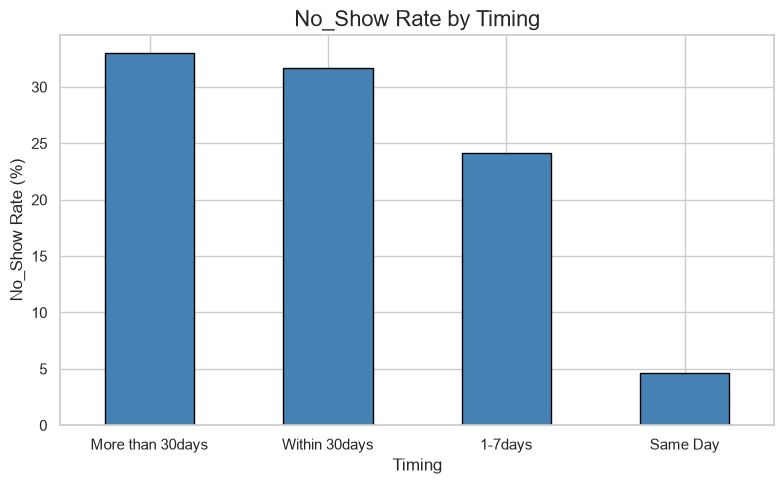

In [ ]:
# No_Show rate by Timing (Most important features)
rate_by_timing = Hd.groupby('Timing')['No_Show_Binary'].mean().sort_values(ascending=False).mul(100).round(2)
ax=rate_by_timing.plot(kind='bar', figsize=(8,5), color='steelblue', edgecolor='black')
plt.title('No_Show Rate by Timing', fontsize=16)
plt.xlabel('Timing')
plt.ylabel('No_Show Rate (%)')
plt.xticks(rotation=0)
save('01_no_show_rate_by_timing')

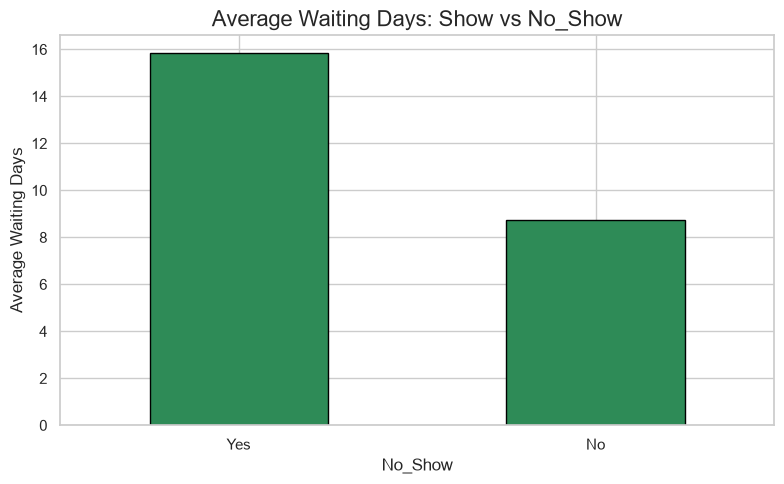

In [7]:
avg_waiting_days = Hd.groupby('No_Show')['Waiting_Days'].mean().sort_values(ascending=False).round(2)
ax=avg_waiting_days.plot(kind='bar', figsize=(8,5), color='seagreen', edgecolor='black')
ax.set_title('Average Waiting Days: Show vs No_Show', fontsize=16)
plt.xlabel('No_Show')
plt.ylabel('Average Waiting Days')
plt.xticks(rotation=0)
save('02_avg_waiting_days_show_vs_no_show')


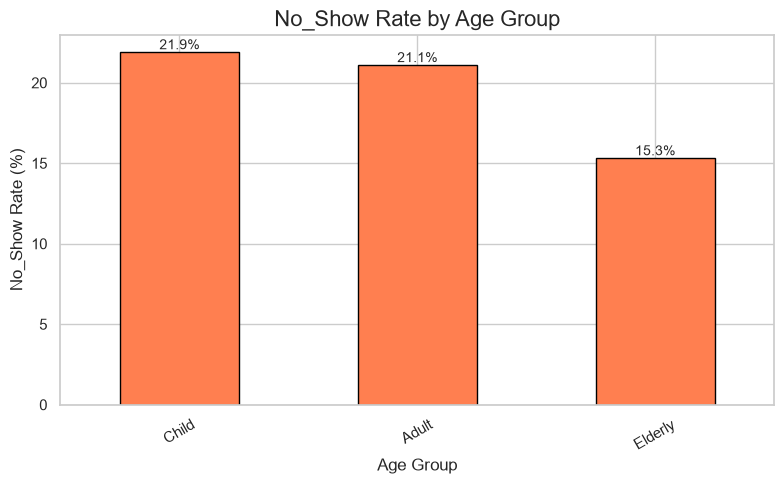

In [8]:
rate = Hd.groupby('Age_Group')['No_Show_Binary'].mean().sort_values(ascending=False).mul(100).round(2)
ax=rate.plot(kind='bar', figsize=(8,5), color='coral', edgecolor='black')
ax.bar_label(ax.containers[0], fmt='%.1f%%', fontsize=10)
plt.title('No_Show Rate by Age Group', fontsize=16)
plt.xlabel('Age Group')
plt.ylabel('No_Show Rate (%)')
plt.xticks(rotation=30)
save('03_no_show_rate_by_age_group')

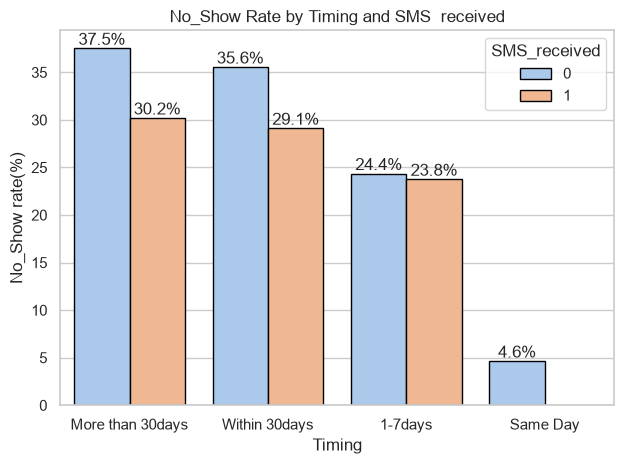

In [9]:
rate = (Hd.groupby(['Timing', 'SMS_received'])['No_Show_Binary'].mean().sort_values(ascending=False).mul(100).reset_index())
ax = sns.barplot(data=rate, x='Timing', y='No_Show_Binary', hue='SMS_received', palette='pastel', edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%")
plt.title("No_Show Rate by Timing and SMS  received")
plt.ylabel("No_Show rate(%)")
save('04_noshow_timing_x_sms')

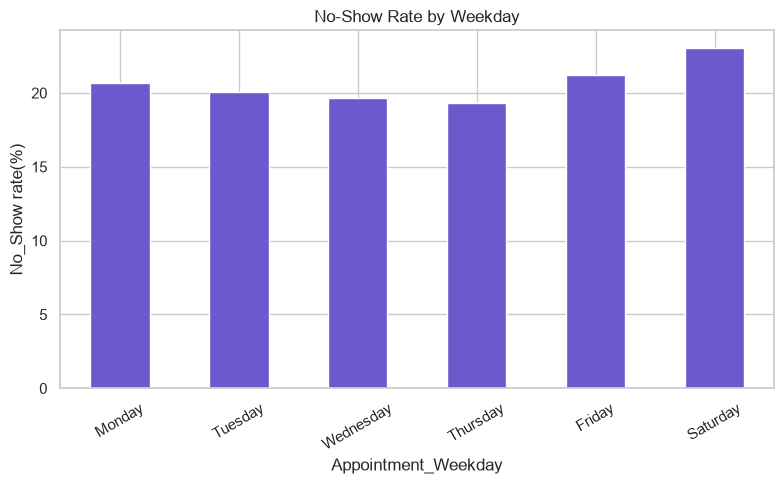

In [10]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", 'Friday', 'Saturday']
rate = (Hd.groupby("Appointment_Weekday")["No_Show_Binary"].mean().mul(100).reindex(order).dropna())
ax = rate.plot(kind="bar", color="slateblue", figsize=(8,5))
plt.title('No-Show Rate by Weekday')
plt.ylabel('No_Show rate(%)')
plt.xticks(rotation=30)
save("05_noshow_by_weekday")

**Insights & Recommendations**

### 1. Executive Summary

Analysis of 110,519 medical appointments showed that **waiting time** is the strongest driver of patient no-shows. Patients who missed their appointments waited nearly twice as long on average (14.8 days vs 7.8 days). No-show rates rose steadily with longer waits, reaching 33% when patients waited more than 30 days. SMS reminders significantly reduced no-shows among patients with longer waiting times. Elderly patients were the most reliable group (15.3% no-show rate), while children and adults had higher rates. These findings highlight clear operational opportunities to improve appointment attendance.

---

### 2. Key Insights

**Insight 1: Waiting time is the dominant driver of no-shows**  
Patients who no-showed waited almost twice as long as those who attended (14.8 days vs 7.8 days). The no-show rate increased consistently with waiting time:
- Same day: 21.4%
- 1–7 days: 25.0%
- Within 30 days: 32.0%
- More than 30 days: 33.0%

**Insight 2: SMS reminders are effective when waiting time is long**  
After controlling for waiting time, SMS had a clear protective effect:
- For waits of 8–30 days: no-show rate dropped from 36.1% to 29.2% with SMS
- For waits over 30 days: no-show rate dropped from 37.5% to 30.3% with SMS  

The overall higher no-show rate among patients who received SMS was due to confounding — longer waits were more likely to receive reminders.

**Insight 3: Age significantly influences attendance**  
- Elderly patients: 15.3% no-show rate  
- Adults: 21.1%  
- Children: 21.9%  

Elderly patients were meaningfully more reliable than younger groups.

**Insight 4: Socio-economic and clinical factors**  
- Patients on Scholarship (Bolsa Família) had a higher no-show rate (23.7% vs 19.8%).  
- Patients with Hypertension (17.3%) or Diabetes (18.0%) showed slightly better attendance than those without these conditions.  
- Alcoholism showed no meaningful difference.  
- Higher levels of Handicap were associated with higher no-show rates.

**Insight 5: Secondary patterns**  
- Saturday had the highest no-show rate (23.1%), while Thursday had the lowest (19.3%).  
- Gender showed almost no difference (Female 20.3%, Male 20.0%).

---

### 3. Practical Recommendations

**Recommendation 1: Reduce maximum waiting time**  
Prioritize scheduling appointments within 7–14 days whenever possible. Longer waits are strongly associated with higher no-show rates and represent the biggest operational lever for improvement.

**Recommendation 2: Strengthen SMS strategy for longer waits**  
Ensure that every patient with a waiting time longer than 7 days receives at least one SMS reminder. Consider adding a second reminder closer to the appointment date for high-risk groups.

**Recommendation 3: Focus extra support on higher-risk segments**  
Develop light-touch confirmation or reminder processes for:
- Children and working-age adults  
- Patients receiving Scholarship benefits  

Elderly patients already show good attendance and require less additional intervention.

**Recommendation 4: Monitor performance weekly**  
Track no-show rates by waiting-time band and age group. Set a realistic internal target to reduce the overall no-show rate from 20.2% toward 17% or lower.

---

### 4. Limitations

- The dataset comes from Brazilian public hospitals in 2016. Results may not fully generalize to other countries or current healthcare systems.  
- Some “Came earlier” records (negative waiting days) appear to be data-quality issues.  
- The analysis shows strong associations but cannot prove causation.  
- Important variables such as distance to the clinic, reason for appointment, and previous no-show history were not available.

---

### 5. Next Steps

- Translate the key business questions into SQL for reproducible reporting.  
- Build an interactive Power BI dashboard for hospital stakeholders.  
- Explore a simple predictive model to flag high-risk appointments in advance.
